### Assignment Tasks
Task 1 — Data Import & Setup
- Import CSV using Pandas
- Check/convert data types
- Convert date columns to datetime
- Use NumPy arrays for basic array operations


In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [94]:
df=pd.read_csv(r"C:\Users\indra\Downloads\social_media_engagement_5000.csv")

In [95]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [109]:
df['posted_at']=pd.to_datetime(df['posted_at'],dayfirst=True)

In [110]:
share_array=df['shares'].to_numpy()
share_array

array([1157., 1807.,  955., ...,  167., 1713., 1798.], shape=(5000,))

In [111]:
mean_array=np.nanmean(share_array)
mean_array

np.float64(1002.6294845360825)

In [112]:
df['age'].median()

np.float64(38.0)

### Task 2 — Data Cleaning
#### Cleaning Missing Data
- Detect missing values (isnull(), isna())
- Handle using: dropna(), fillna(), median/mode, forward/backward-fill
####  Duplicate Handling
- Identify & remove duplicates

#### Data Formatting
- Fix incorrect data types
- Standardize categories (e.g., gender labels)
- Correct unrealistic values in likes, comments, shares
#### Feature Cleaning
- Extract hashtag count
- Clean sentiment labels


In [113]:
df.isnull().sum()


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [114]:
df['age']=df['age'].fillna(df['age'].median())

In [115]:
df['gender']=df['gender'].fillna('Unknown')

In [116]:
df['shares']=df['shares'].fillna(df['shares'].mean())

In [117]:
df['likes']=df['likes'].fillna(df['likes'].mean())

In [118]:
df['comments']=df['comments'].fillna(df['comments'].median())

In [119]:
df['sentiment']=df['sentiment'].ffill()

In [120]:
df.duplicated().sum()
## no duplicates were found

np.int64(0)

In [121]:
duplicates = df[df.duplicated(keep=False)]
duplicates

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate


In [122]:
df['age']=df['age'].astype(int)
df['likes']=df['likes'].astype(int)
df['comments']=df['comments'].astype(int)
df['shares']=df['shares'].astype(int)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [123]:
df['gender']=df['gender'].str.capitalize()

In [124]:
for i in df.select_dtypes(include=['str','object']).columns:
    df[i] = df[i].astype(str).str.strip().str.title()

In [125]:
 df[["likes", "comments", "shares"]].describe()

,likes,comments,shares
count,5000.000000,5000.000000,5000.000000
mean,10107.042400,1502.039800,1002.610600
std,5702.293011,856.393312,570.852972
min,10.000000,0.000000,0.000000
25%,5235.000000,792.000000,511.000000
50%,10107.000000,1497.000000,1002.000000
75%,14959.000000,2235.250000,1483.000000
max,19998.000000,2999.000000,1999.000000


### no unrealistic values found in these columns.

In [126]:
hashtag_count=df['hashtags'].str.count('#').sum()
hashtag_count

np.int64(9993)

### total hashtag count 9993

In [127]:
df['sentiment']=df['sentiment'].str.strip().str.title()


In [128]:
df.columns=df.columns.str.strip()

### Task 3 — Data Exploration using Pandas
Perform the following:
- View dataset structure using head(), tail(), shape, and columns.
- Check data types and info with info() and dtypes.
- Generate summary statistics using describe().
- Analyze categorical distributions using value_counts(), unique(), and nunique().
- Create a correlation matrix for numeric fields.
- Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).


In [129]:
df.head()


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#Foodie #Travel #Love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#Fitness,0.201493
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#Foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#Music #Foodie #Fun,0.106195
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#Travel,2.777372


In [130]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#Travel #Fun,0.466761
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#Foodie #Reels,0.621155
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#Lifestyle #Tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#Reels #Love #Fitness,0.223518
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#Foodie #Lifestyle #Fashion,1.203527


In [131]:
df.shape

(5000, 19)

In [132]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [133]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [134]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10107.042400,1502.039800,1002.610600,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.000000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10107.000000,1497.000000,1002.000000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.000000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5702.293011,856.393312,570.852972,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [135]:
df['post_type'].value_counts()

post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64

In [136]:
df['post_type'].unique()

<ArrowStringArray>
['Image', 'Reel', 'Text', 'Video']
Length: 4, dtype: str

In [137]:
df['post_type'].nunique()

4

In [138]:
df.corr(numeric_only=True)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,is_verified,engagement_rate
user_id,1.000000,-0.006688,0.020051,0.025812,-0.033395,0.013786,-0.016847,0.015326,0.010124,0.004058,-0.004282
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013864,0.005542,0.013322,-0.024894,-0.000079,0.008039
post_id,0.020051,-0.013153,1.000000,0.014527,-0.010540,0.001874,0.018374,-0.007709,-0.002844,0.025208,0.010139
likes,0.025812,-0.036322,0.014527,1.000000,-0.018420,0.004648,0.008711,0.007953,-0.022981,-0.016200,0.093520
comments,-0.033395,-0.007284,-0.010540,-0.018420,1.000000,0.006138,-0.016351,-0.009395,-0.011733,-0.012398,0.000051
shares,0.013786,0.013864,0.001874,0.004648,0.006138,1.000000,0.014672,-0.005086,-0.010738,0.007091,0.021729
watch_time_sec,-0.016847,0.005542,0.018374,0.008711,-0.016351,0.014672,1.000000,-0.004335,0.002761,0.012326,-0.001148
impression_count,0.015326,0.013322,-0.007709,0.007953,-0.009395,-0.005086,-0.004335,1.000000,-0.015513,0.008317,-0.232226
follower_count,0.010124,-0.024894,-0.002844,-0.022981,-0.011733,-0.010738,0.002761,-0.015513,1.000000,-0.017808,0.002292
is_verified,0.004058,-0.000079,0.025208,-0.016200,-0.012398,0.007091,0.012326,0.008317,-0.017808,1.000000,0.005528


In [139]:
df.groupby(['post_type','country'])['likes'].mean()

post_type  country  
Image      Australia     9719.102362
           Brazil        9285.879433
           Canada        9702.114286
           France       11202.846154
           Germany      10285.217391
           India        10048.110236
           Japan         9677.427184
           Uae          10890.619835
           Uk            9813.317073
           Usa          10516.883333
Reel       Australia    10215.364407
           Brazil        9956.472000
           Canada       10235.152672
           France       10104.286885
           Germany       9490.892857
           India         9591.818750
           Japan        10286.768000
           Uae           9923.758621
           Uk           10332.927419
           Usa          10341.512397
Text       Australia    10356.930233
           Brazil       10262.837398
           Canada       10045.650943
           France        9735.569106
           Germany      10491.156716
           India        10111.590909
           Japan 

### Task 4 — Data Wrangling 
Use merge, concat, or join if combining DataFrames.
- Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.
- Perform groupby summaries by post_type, country, and sentiment.


In [140]:
combined_rows = pd.concat([df_part1, df_part2], ignore_index=True)

NameError: name 'df_part1' is not defined

In [151]:
df['engagement_score']=df['likes']+df['comments']+df['shares']

In [152]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_score,hashtag_counts
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,...,44650,2022-12-17,81734,False,Mobile,Negative,#Foodie #Travel #Love,0.190862,8522,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,...,80216,2023-06-02,5963,False,Mobile,Negative,#Fitness,0.201493,16163,1
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,...,44858,2023-05-07,501783,False,Tablet,Positive,#Foodie,0.137345,6161,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,...,70455,2023-02-12,480212,False,Mobile,Negative,#Music #Foodie #Fun,0.106195,7482,3
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,...,6019,2023-05-23,383936,False,Mobile,Negative,#Travel,2.777372,16717,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,...,42977,2022-06-25,646147,False,Mobile,Positive,#Travel #Fun,0.466761,20060,2
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,...,34196,2022-11-18,584603,False,Desktop,Negative,#Foodie #Reels,0.621155,21241,2
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1497,167,...,23680,2023-04-06,483550,False,Desktop,Positive,#Lifestyle #Tech,0.679688,15151,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,...,89013,2022-05-16,183295,False,Tablet,Positive,#Reels #Love #Fitness,0.223518,19896,3


In [143]:
df['hashtag_counts']=df['hashtags'].str.count('#')

In [144]:
summary_stats = df.groupby(['post_type','country','sentiment']).agg(
    avg_likes=('likes', 'mean'),
    total_shares=('shares', 'sum'),
    post_count=('likes', 'count')
).reset_index()

print(summary_stats)

    post_type    country sentiment     avg_likes  total_shares  post_count
0       Image  Australia  Negative   8251.600000         19563          20
1       Image  Australia   Neutral   9754.311111         51254          45
2       Image  Australia  Positive  10166.935484         67627          62
3       Image     Brazil  Negative   7913.875000         24096          24
4       Image     Brazil   Neutral   8409.695652         51789          46
..        ...        ...       ...           ...           ...         ...
115     Video         Uk   Neutral  10291.111111         38823          36
116     Video         Uk  Positive   9011.400000         61750          65
117     Video        Usa  Negative  10290.450000         20993          20
118     Video        Usa   Neutral   9807.365854         37762          41
119     Video        Usa  Positive   9421.490909         61091          55

[120 rows x 6 columns]


In [145]:
print('summary by post type:\n',df.groupby('post_type')[['likes','shares','comments']].mean(),
      '\n\nsummary by country:\n',df.groupby('country')[['likes','shares','comments']].mean(),
     '\n\nsummary by sentiment:\n',df.groupby('sentiment')[['likes','shares','comments']].mean())

summary by post type:
                   likes       shares     comments
post_type                                        
Image      10104.903769  1019.000802  1525.235766
Reel       10037.855027   981.738114  1504.187062
Text       10100.195181  1013.684337  1499.106024
Video      10188.641633   996.532245  1479.160000 

summary by country:
                   likes       shares     comments
country                                          
Australia  10294.176471  1029.409736  1485.803245
Brazil      9886.722222  1008.601190  1490.434524
Canada     10063.101365   995.894737  1546.582846
France     10372.915323  1051.530242  1478.695565
Germany    10130.528571   972.828571  1531.826531
India       9962.538318  1035.091589  1494.917757
Japan      10088.894068   959.097458  1530.434322
Uae        10227.528827   988.876740  1541.214712
Uk          9935.689655   985.336714  1463.042596
Usa        10122.397206   994.882236  1457.958084 

summary by sentiment:
                   likes      

####  Task 5 — Statistical Analysis  Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers: ● Mean, median, mode ● Standard deviation, variance ● Percentiles ● (Optional) Skewness and kurtosis 

In [146]:
columns_for_analise= [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count",
]
status=df[columns_for_analise].agg(['mean','median','std'])

In [147]:
status

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
mean,10107.042400,1502.039800,1002.610600,4014.503200,0.964356,393698.224800
median,10107.000000,1497.000000,1002.000000,4034.500000,0.253896,388982.000000
std,5702.293011,856.393312,570.852972,2308.096459,5.318029,230927.884535


In [148]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'engagement_score', 'hashtag_counts'],
      dtype='str')

In [149]:
modes=df[columns_for_analise].mode().iloc[0]
modes

likes               10107.000000
comments             1497.000000
shares               1002.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

In [150]:
df[columns_for_analise].describe()
# also we can use df[columns_for_analise].quantile([0.25,0.50.0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,10107.042400,1502.039800,1002.610600,4014.503200,0.964356,393698.224800
std,5702.293011,856.393312,570.852972,2308.096459,5.318029,230927.884535
min,10.000000,0.000000,0.000000,0.000000,0.006363,87.000000
25%,5235.000000,792.000000,511.000000,2017.750000,0.145781,194480.000000
50%,10107.000000,1497.000000,1002.000000,4034.500000,0.253896,388982.000000
75%,14959.000000,2235.250000,1483.000000,6020.250000,0.504794,589744.250000
max,19998.000000,2999.000000,1999.000000,7998.000000,191.504348,799533.000000


In [64]:
df[columns_for_analise].var()

likes                       NaN
comments                    NaN
shares                      NaN
watch_time_sec     8.702231e+06
engagement_rate    2.828143e+01
follower_count              NaN
dtype: float64

In [84]:
print('skewness:\n',df[columns_for_analise].skew(),'\n\nkurtosis:\n',
df[columns_for_analise].kurt())

skewness:
 likes                    NaN
comments                 NaN
shares                   NaN
watch_time_sec     -0.047271
engagement_rate    18.781271
follower_count           NaN
dtype: float64 

kurtosis:
 likes                     NaN
comments                  NaN
shares                    NaN
watch_time_sec      -2.451646
engagement_rate    482.991739
follower_count            NaN
dtype: float64


####  engagement rate having extreme outliers thats why skewness and kurtosis showing highvalue.

### Task 6 — Data Visualization (Min. 8 Plots Required)
Matplotlib
Scatter: likes vs impressions
Line: daily engagement trend
Bar: posts by category
Pie: gender distribution
Histogram: age
Box: engagement rate

Seaborn
Count plot: post type
Bar plot: avg likes by category
Violin: followers vs sentiment
Pair plot: numeric features
Heatmap: correlation matrix
Swarm plot: engagement vs device
Plotly (Interactive)
Interactive line chart/bar chart/bubble/scatter chart


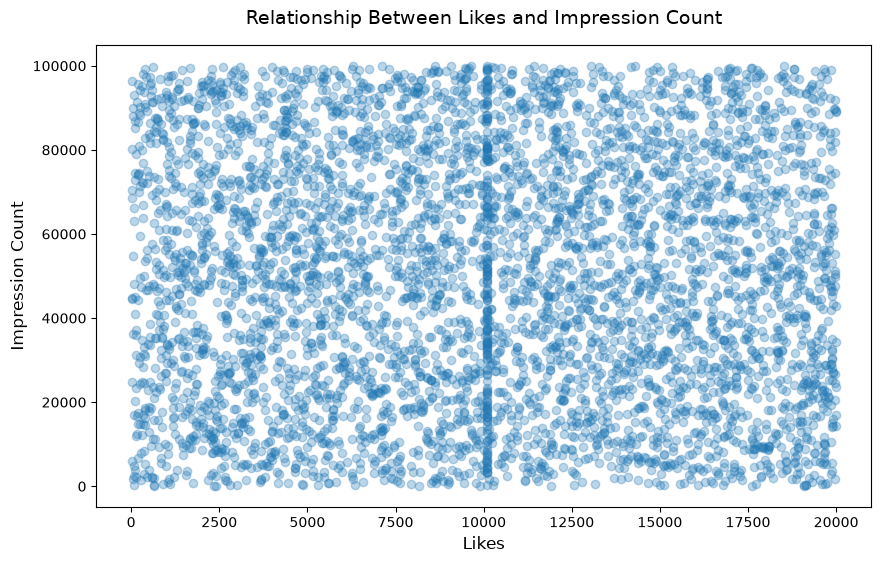

In [273]:
plt.figure(figsize=(10,6))
plt.scatter(x=df['likes'].sort_values(),y=df['impression_count'],alpha=0.3)
plt.title('Relationship Between Likes and Impression Count', fontsize=14, pad=15)
plt.xlabel('Likes', fontsize=12)
plt.ylabel('Impression Count', fontsize=12)
plt.show()

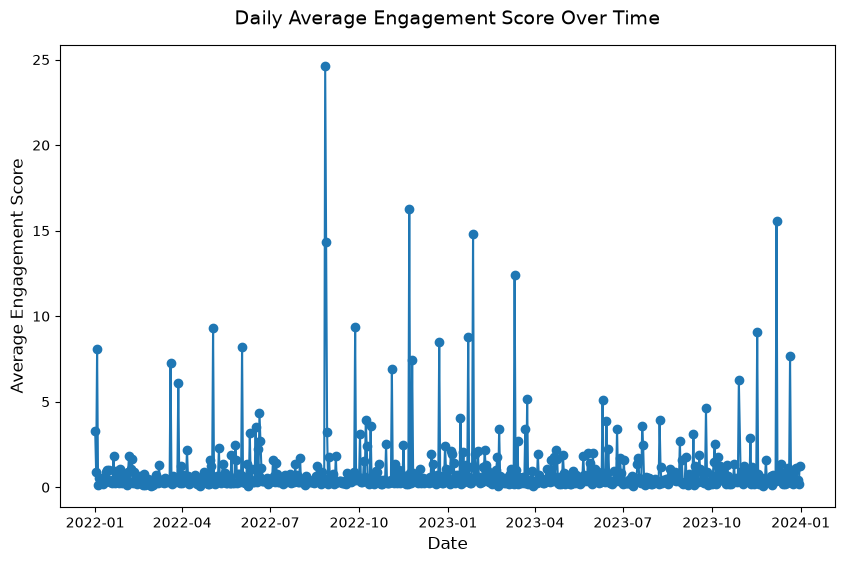

In [227]:
plt.figure(figsize=(10,6),dpi=100)
daily=df.groupby(df['posted_at'])['engagement_rate'].mean()
plt.plot(daily.index,daily.values,marker='o')
plt.title('Daily Average Engagement Score Over Time', fontsize=14, pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Average Engagement Score', fontsize=12)
plt.show()

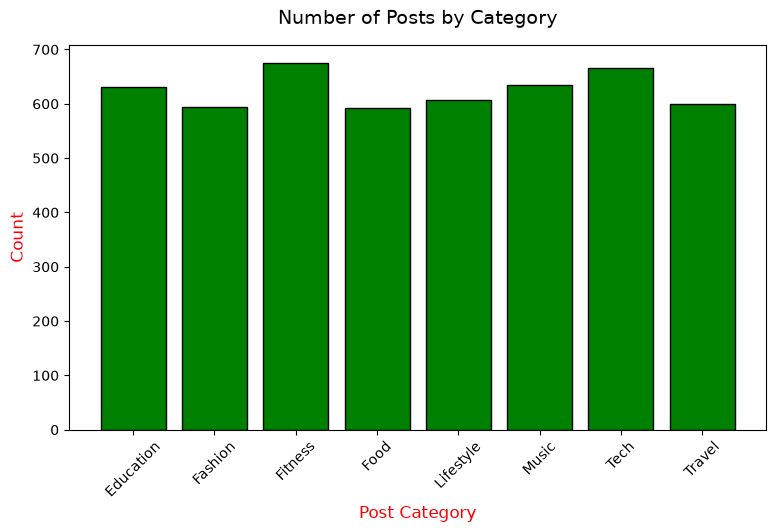

In [182]:
counts= df.groupby('post_category')['likes'].count()

plt.figure(figsize=(9, 5))
plt.bar(counts.index, counts.values, color='green', edgecolor='black')
plt.title('Number of Posts by Category', fontsize=14, pad=15)
plt.xlabel('Post Category', fontsize=12,color='red')
plt.ylabel('Count', fontsize=12,color='red')
plt.xticks(rotation=45)
plt.show()

### top number of posts related is fitness

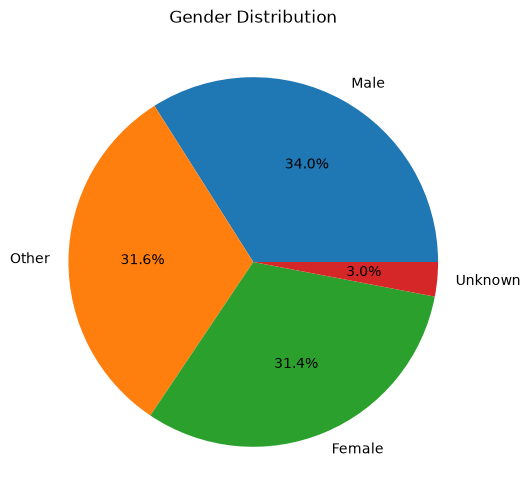

In [212]:
genderdis=df['gender'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(genderdis,labels=gender_dis.index,autopct='%1.1f%%')
plt.title('Gender Distribution')
plt.show()

#### it shows males is more than other genders

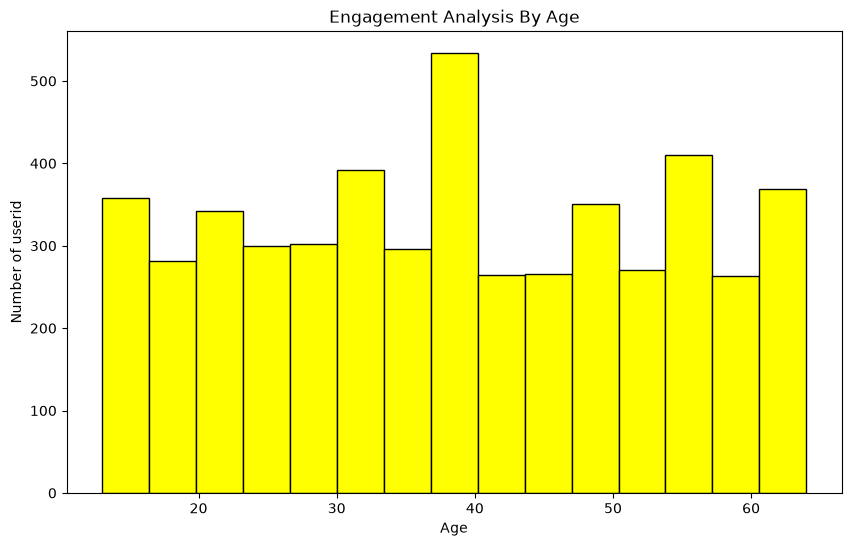

In [268]:
plt.figure(figsize=(10,6))
plt.hist(x=df['age'],bins=15,color='yellow',edgecolor='black')
plt.title('Engagement Analysis By Age')
plt.xlabel('Age')
plt.ylabel('Number of userid')
plt.show()

###  it showing age inside 35 to 45 having the highest users

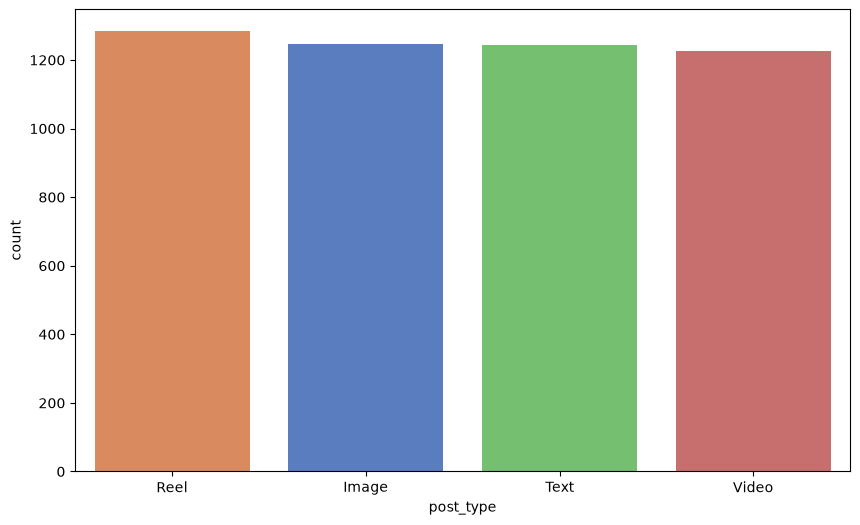

In [222]:
plt.figure(figsize=(10, 6), dpi=100)
sns.countplot(
    data=df,
    x='post_type',
    order=df['post_type'].value_counts().index,
    palette='muted',hue='post_type')
plt.show()

### reels having the top counts.

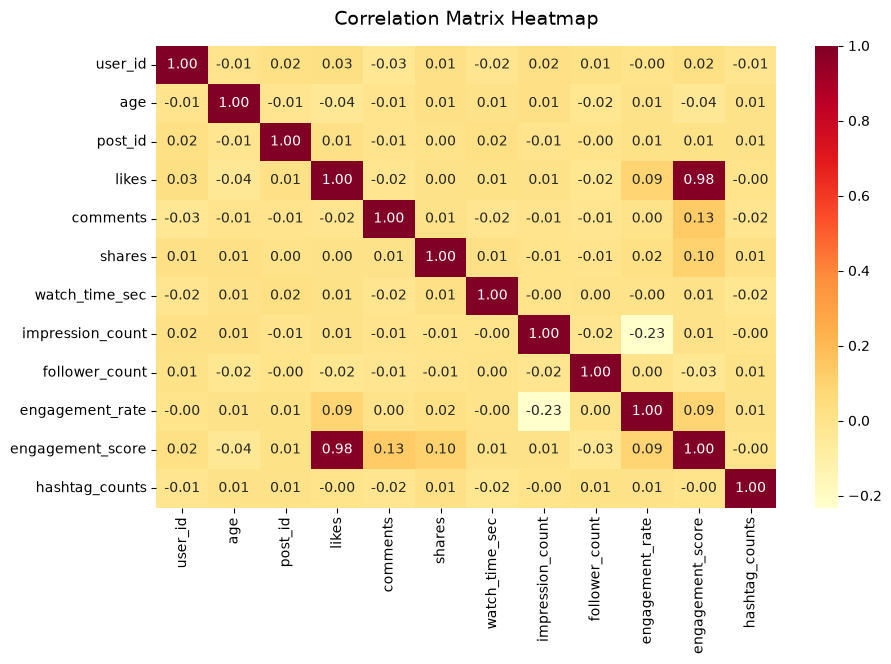

In [265]:
plt.figure(figsize=(10,6))
numeric_df = df.select_dtypes(include=['float64', 'int64'])
metrix=numeric_df.corr()
sns.heatmap(metrix,annot=True,cmap='YlOrRd',fmt='.2f')
plt.title('Correlation Matrix Heatmap', fontsize=14, pad=15)
plt.show()

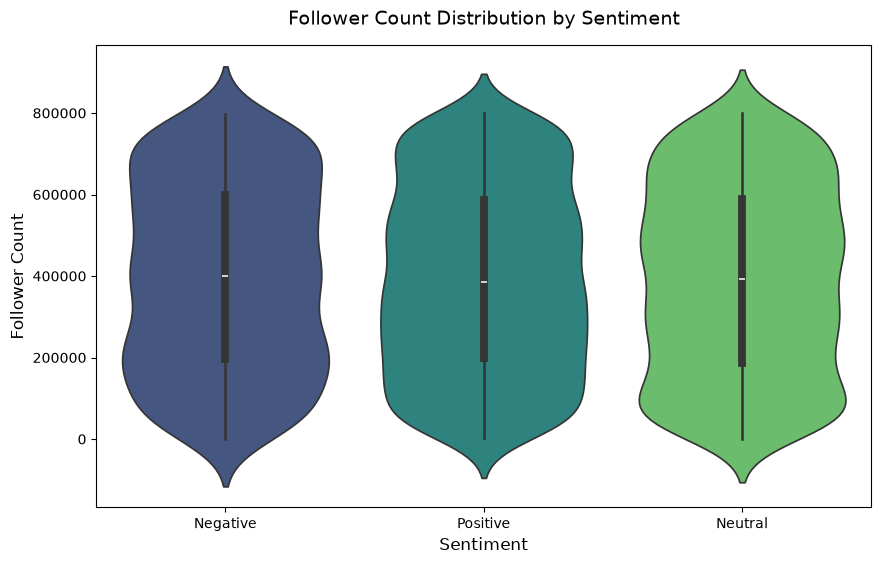

In [278]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='sentiment', y='follower_count',hue='sentiment', palette='viridis')
plt.title('Follower Count Distribution by Sentiment', fontsize=14, pad=15)
plt.xlabel('Sentiment', fontsize=12)
plt.ylabel('Follower Count', fontsize=12)
plt.show()

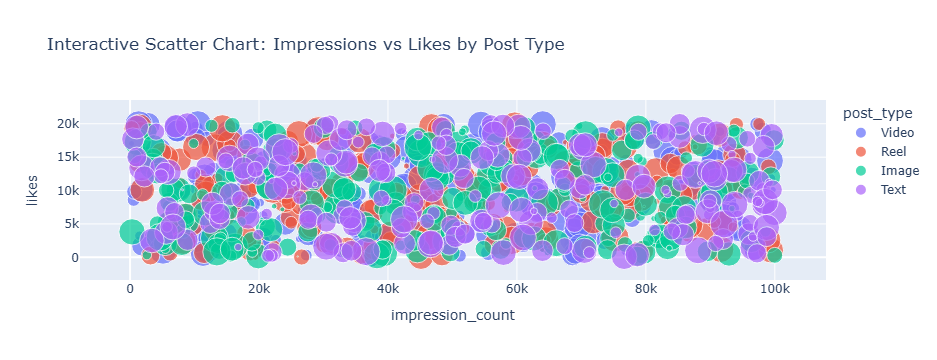

In [290]:
fig_plotly = px.scatter(
    df.sample(n=min(1000, len(df))), 
    x="impression_count", 
    y="likes", 
    color="post_type", 
    size="shares" if "shares" in df.columns else None, 
    hover_data=["post_category"] if "post_category" in df.columns else None, 
    title="Interactive Scatter Chart: Impressions vs Likes by Post Type"
)
fig_plotly.show()

### Content Performance
Which post types have highest engagement?
Best-performing content category?
Which countries have highest avg engagement rate? 
User Trends
How age affects engagement
Performance difference for verified accounts



In [300]:
print('highest post :\n',df.groupby('post_type')['engagement_rate'].mean(),'\n\nbest performing content:\n',
df.groupby('post_category')['engagement_rate'].mean(),'\nHighest avg engagement rate:\n',
df.groupby('country')['engagement_rate'].mean())


highest post :
 post_type
Image    0.895646
Reel     0.783047
Text     1.064549
Video    1.122365
Name: engagement_rate, dtype: float64 

best performing content:
 post_category
Education    0.844222
Fashion      0.807109
Fitness      0.865628
Food         1.358628
Lifestyle    1.091019
Music        0.888803
Tech         1.160475
Travel       0.702223
Name: engagement_rate, dtype: float64 
Highest avg engagement rate:
 country
Australia    1.324339
Brazil       1.540704
Canada       0.916659
France       1.146402
Germany      0.759000
India        0.655005
Japan        0.769623
Uae          1.112352
Uk           0.850966
Usa          0.576580
Name: engagement_rate, dtype: float64


#### post type that having highest engagement rate is video. then text is having second position,reels and image having lower engagement rate comparing to text and video

#### food ,lyfestyle and tech having the top 3 performing content.
#### brazil,australia,france and uae are the top 4 highest engagementrate countries

### User Trends


In [312]:
print('age by engagement rate:\n',df.groupby('age')['engagement_rate'].mean().sort_values(ascending=False).head(10),'\n\nverified account:\n',
      df.groupby('is_verified')['engagement_rate'].mean())


age by engagement rate:
 age
24    2.897327
55    2.599106
51    2.397295
48    1.675878
50    1.552627
41    1.540070
35    1.521596
47    1.402015
42    1.350772
63    1.303909
Name: engagement_rate, dtype: float64 

verified account:
 is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


#### User Demographics: Engagement peaks strongly among younger adults around age 24 (2.89%), as well as mature demographics in the 50–55 age bracket.

#### Account Verification: Verified accounts achieve slightly higher average engagement (1.05%) compared to unverified accounts (0.95%).

### Behavioral Insights
Best time of day for impressions


Device type impact on watch time




In [316]:
df.groupby('posted_at')['impression_count'].mean().sort_values(ascending=False).head(10)

posted_at
2023-12-02    98263.500000
2023-08-10    90304.500000
2023-09-06    89909.000000
2023-02-22    84897.000000
2023-12-16    81594.000000
2023-10-01    80315.142857
2023-10-21    76528.857143
2022-03-02    76398.250000
2023-01-08    75693.800000
2022-07-01    75379.400000
Name: impression_count, dtype: float64

#### Top Performing Days: The highest average impression counts are concentrated heavily around late autumn and winter dates—specifically December 2, 2023 (averaging ~98,263 impressions) and August 10, 2023 (~90,304 impressions).

In [318]:
df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

device_type
Mobile     4087.830760
Tablet     3979.736429
Desktop    3974.792521
Name: watch_time_sec, dtype: float64

#### Mobile Leads Watch Time: Users on Mobile devices record the highest average watch time (4,087.83 seconds), followed by Tablets (~3,979 seconds) and Desktops (~3,974 seconds)Mobile devices drive the highest content consumption duration. This highlights that your audience predominantly consumes video and media content on-the-go via smartphones, making mobile-first content optimization crucial for maximizing watch retention.

###  Sentiment Analysis
Which sentiment performs best


Behavior of negative/neutral sentiment posts


In [320]:
df.groupby('sentiment')['engagement_rate'].mean()

sentiment
Negative    1.015169
Neutral     0.973683
Positive    0.937632
Name: engagement_rate, dtype: float64

#### Insight: Content that provokes negative emotions, debates, strong reactions, or critical discussions tends to drive slightly higher engagement rates than positive or neutral posts, highlighting the tendency for provocative or critical content to capture more audience interaction.

### High Conversational Depth: Neutral sentiment posts consistently yield the highest average engagement rates.